# Broken double well $V=0.1X^4-0.3X^2+0.6X$: analysis

Characterises the broken double well with coherent-state probes: a single scan of 21 probe
centres, reconstructed with $|n|\le2$ harmonics. The tilt $v_1=0.6$ is large enough that the
programmed potential has a single stationary point, at $X=-1.57$, outside the topology window.
Produces the broken-well curves of main-text Fig. 3(a), its topology fraction and stationary
points, its parity test, and the broken-well rows of the SM acquisition, acceptance and Sim
tables.

**Input:** `broken_tdw.zip` (raw single shots and the two bracketing vacuum calibrations) in the same folder as this notebook.
**Output:** tables, figures and `paper_values.json` in `results_broken_double_well/`.

| § | content | used in |
|---|---|---|
| 0 | setup: imports and library functions | — |
| 1 | configuration and raw data | SM *Acquisition* |
| 2 | measurement: momentum scale, probe width, probe-averaged force, raw-shot bootstrap | SM *Measurement*, *Uncertainties* |
| 3 | compiled circuit: $K_g$ from the rotation angles run, and its exact channels | SM *Bosonic QSP construction* |
| 4 | pointwise force reconstruction and Sim, Morse-rule cross-check | SM *Pointwise force reconstruction* |
| 5 | band-limited target | SM *Reference curves* |
| 6 | stationary points and parity test | main text; SM *Double-well gates* |
| 7 | acceptance and post-selection | SM *Acceptance and post-selection* |
| 8 | agreement with Sim: band coverage and force errors | SM *Agreement with Sim* |
| 9 | values quoted in the paper | main text, SM |
| 10 | figure panels | main-text Fig. 3(a) |

**Conventions shared by the five analysis notebooks.** Fourier interval $|X|\le2$
(period $L=4$, $\gamma=\pi/2$); probe attenuation $H_n=e^{-\sigma_X^2k_n^2/2}$ with the
measured probe variance $\sigma_X^2$; noise-gain cap $1/H_n\le G=20$; uncertainties from
2000 raw-shot bootstrap replicas; functional-form fits (cubic, Morse) confined to the largest
window $|X|\le W$ over which a simulated perfect device (Sim plus the measured noise) is
consistent with the form (median $p\ge0.10$ at $W$ and at every smaller window); double-well
topology on $|X|\le1.5$.

Run top to bottom. Every number quoted in the paper is collected in `PAPER`, printed
between `===== PAPER VALUES` markers in section 9 and written to `paper_values.json` in the
output folder; `extract_outputs.py` gathers these blocks from all five notebooks.

## 0. Setup
Imports and library functions.

In [1]:
from pathlib import Path
import io, zipfile, re, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2 as chi2_dist
from numpy.polynomial.hermite import hermgauss

def sha256_file(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):
            h.update(block)
    return h.hexdigest()

def signed_label(name):
    m=re.search(r"alpha-([^_]+)_compressed",Path(name).name)
    if not m:
        raise ValueError(f"cannot parse probe label from {name}")
    s=m.group(1).lower()
    sign=-1.0 if s.startswith("m") else 1.0
    core=s[1:] if s.startswith("m") else s
    return sign*float(core)

def clock_seconds(name):
    m=re.match(r"(\d{2})-(\d{2})-(\d{2})_",Path(name).name)
    if not m:
        return np.nan
    h,mn,s=map(int,m.groups())
    return h*3600+mn*60+s

def jeffreys_binomial_se(k,n):
    k=np.asarray(k,float); n=np.asarray(n,float)
    a=k+0.5; b=n-k+0.5
    return np.sqrt(a*b/((a+b)**2*(a+b+1.0)))

# ---------------------------------------------------------------------
#  Crosshair calibration: probe width and momentum scale.
#
#  The tomography gate is ECD-3, so a vacuum crosshair is a Gaussian of width
#  w_vac = 1/3 in the swept DAC variable (supplement, "Probe width").
#  The crosshair is a characteristic-function cut of the undisplaced probe, so
#  a width-free fit measures the probe directly:
#
#      sigma_X^2 = (1/2) (w_vac / w)^2 ,
#
#  the quantity the Morse notebook reads off its probe cut.  The
#  same fit gives the readout contrast A, and with the DAC-to-phase-space scale
#  fixed by w_vac the momentum-conversion denominator is
#
#      den = sqrt(2) * A / w_vac .
#
#  A second fit with the width pinned at w_vac (a vacuum probe assumed) is kept
#  as the reference; its relative error is carried by den.  USE_MEASURED_WIDTH
#  in the configuration cell selects the measured width (the convention of
#  every gate) or the pinned reference (sigma_X^2 = 1/2).
# ---------------------------------------------------------------------
CROSSHAIR_W_FIXED = 1.0/3.0        # ECD-3 vacuum crosshair width, by construction
CROSSHAIR_ENFORCE_WIDTH = True     # keep the pinned-width reference fit; same in every gate notebook


def fit_crosshair_blob(blob, name, w_fixed=None, enforce=None):
    wf = CROSSHAIR_W_FIXED if w_fixed is None else float(w_fixed)
    en = CROSSHAIR_ENFORCE_WIDTH if enforce is None else bool(enforce)
    with np.load(io.BytesIO(blob)) as z:
        x  = np.asarray(z["xdata"], float)
        y0 = np.asarray(z["ydata_0"], float)
        y1 = np.asarray(z["ydata_1"], float) if "ydata_1" in z.files else None

    def g_fixed(x, b, A, x0):    return b + A*np.exp(-0.5*((x-x0)/wf)**2)
    def g_free(x, b, A, x0, w):  return b + A*np.exp(-0.5*((x-x0)/w)**2)

    def one(y):
        edge = np.r_[y[:4], y[-4:]]
        p0 = [float(edge.mean()), float(y.max()-edge.mean()), 0.0]

        # width free: the probe width and the readout contrast
        try:
            qopt, qcov = curve_fit(g_free, x, y, p0=p0+[wf], maxfev=30000)
            w_free = float(abs(qopt[3]))
            w_se   = float(np.sqrt(max(qcov[3, 3], 0.0))) if np.all(np.isfinite(qcov)) else np.nan
            s2   = 0.5*(wf/w_free)**2
            s2_se = (wf**2/w_free**3)*w_se if np.isfinite(w_se) else np.nan
            den_meas = float(qopt[1]*np.sqrt(2)/wf)
        except Exception:
            w_free = w_se = s2 = s2_se = den_meas = np.nan

        if en:
            popt, pcov = curve_fit(g_fixed, x, y, p0=p0, maxfev=30000)
            b, A, x0 = popt; w = wf
            grad = np.array([0.0, np.sqrt(2)/w, 0.0])
            gfun = g_fixed
        else:
            popt, pcov = curve_fit(g_free, x, y, p0=p0+[wf], maxfev=30000)
            b, A, x0, w = popt; w = abs(w)
            grad = np.array([0.0, np.sqrt(2)/w, 0.0, -A*np.sqrt(2)/(w*w)])
            gfun = g_free
        den = A*np.sqrt(2)/w
        var = float(grad@pcov@grad) if np.all(np.isfinite(pcov)) else 0.0
        se  = float(np.sqrt(max(var, 0.0)))

        # ---- momentum scale, applied here so that every force, every
        #      bootstrap draw and every table downstream is consistent -----
        #  contrast A from the width-free fit, DAC-to-phase-space scale from
        #  w_vac: den = sqrt(2) A_free / w_vac.  Its error keeps the relative
        #  error of the pinned-width fit.
        den_used, se_used = den, se
        if USE_MEASURED_WIDTH and np.isfinite(den_meas) and den_meas > 0:
            se_used = se*den_meas/den if den else se      # relative error preserved
            den_used = den_meas

        return {"den": float(den_used), "se": float(se_used),
                "den_pinned_width": float(den),
                "den_measured_width": float(den_meas),
                "measured_width_used": bool(USE_MEASURED_WIDTH),
                "params": popt, "cov": pcov, "g": gfun,
                "peak": float(b+A), "width": float(abs(w)),
                "width_free": w_free, "width_free_se": w_se,
                "sigma_X2": s2, "sigma_X2_se": s2_se,
                "den_measured_vs_pinned": float(den_meas/den) if den else np.nan,
                "calibration_mode": (("probe width measured: width-free fit, den = sqrt(2) A / w_vac"
                                  if USE_MEASURED_WIDTH else f"width pinned at {wf:.6f} (vacuum probe assumed)")
                                 if en else "width free, contrast and DAC scale both fitted (NOT the convention)")}

    p0_ = one(y0)
    p1_ = one(y1) if y1 is not None else None
    if np.isfinite(p0_["sigma_X2"]):
        SIGMA2_MEASURED.append(float(p0_["sigma_X2"]))   # primary channel only
    return {"name": name, "x": x, "y0": y0, "y1": y1,
            "primary": p0_, "secondary": p1_, "g": p0_["g"]}


def load_science_blob(blob, name):
    with np.load(io.BytesIO(blob)) as z:
        shot=np.asarray(z["single_shot"],float)
        pre=np.asarray(z["preselect"],float)
        x=np.asarray(z["y_displace"],float)
        saved_pg=float(z["num_in_g"]) if "num_in_g" in z.files else np.nan

        if shot.shape!=pre.shape or shot.ndim!=2:
            raise ValueError(f"{name}: invalid single_shot/preselect shape")

        accepted=(pre==0)
        n1=np.sum((shot==1)&accepted,axis=0).astype(int)
        n0=np.sum((shot==0)&accepted,axis=0).astype(int)
        nr=np.sum(~accepted,axis=0).astype(int)

        if "masked_0" in z.files:
            masked=np.asarray(z["masked_0"],float)
            expected=np.where(accepted,shot,np.nan)
            if not np.array_equal(np.isfinite(masked),np.isfinite(expected)):
                raise ValueError(f"{name}: masked_0 mask differs from preselect==0")
            finite=np.isfinite(masked)
            if finite.any() and np.max(np.abs(masked[finite]-expected[finite]))>0:
                raise ValueError(f"{name}: masked_0 values differ from accepted single_shot")

        pg=float(np.sum(n0+n1)/(shot.shape[0]*shot.shape[1]))
        if np.isfinite(saved_pg) and abs(pg-saved_pg)>1e-12:
            raise ValueError(f"{name}: raw p_g={pg} differs from stored num_in_g={saved_pg}")

    return {
        "name":name,"label":signed_label(name),
        "mu":0.2*signed_label(name),  # probe centres are labelled in steps of 0.2 in X
        "clock":clock_seconds(name),
        "x":x,"n0":n0,"n1":n1,"nr":nr,
        "N":shot.shape[0],"ncf":shot.shape[1],
        "pg":pg
    }

def cf_fit(rec, order):
    x=np.asarray(rec["x"],float)
    n0=np.asarray(rec["n0"],float); n1=np.asarray(rec["n1"],float)
    n=n0+n1
    y=n1/np.maximum(n,1)
    se=jeffreys_binomial_se(n1,n)
    scale=float(np.max(np.abs(x)))
    u=x/scale
    A=np.column_stack([u**j for j in range(order+1)])
    Aw=A/se[:,None]; yw=y/se
    beta,_,rank,sing=np.linalg.lstsq(Aw,yw,rcond=None)
    cov=np.linalg.pinv(Aw.T@Aw,rcond=1e-12)
    pred=A@beta
    resid=(y-pred)/se
    dof=max(len(y)-rank,1)
    return {
        "order":order,"slope":float(beta[1]/scale),
        "slope_se":float(np.sqrt(max(cov[1,1],0))/scale),
        "chi2":float(resid@resid),"dof":int(dof),
        "p":float(chi2_dist.sf(resid@resid,dof)),
        "condition":float(np.linalg.cond(Aw)),
        "coef":beta,"scale":scale,"pred":pred,"y":y,"se":se
    }

def bootstrap_raw(records, cal0, cal1, frac, B=2000, seed=20260824, order=5):
    rng=np.random.default_rng(seed)
    nr=len(records)
    Fb=np.empty((B,nr),float)
    Pgb=np.empty((B,nr),float)
    for b in range(B):
        d0=rng.normal(cal0["den"],cal0["se"])
        d1=rng.normal(cal1["den"],cal1["se"])
        for i,r in enumerate(records):
            n0b=np.empty(r["ncf"],int)
            n1b=np.empty(r["ncf"],int)
            for j,(a0,a1,ar) in enumerate(zip(r["n0"],r["n1"],r["nr"])):
                p=np.array([a0,a1,ar],float)/r["N"]
                draw=rng.multinomial(r["N"],p)
                n0b[j],n1b[j]=draw[0],draw[1]
            rr=dict(r)
            rr["n0"]=n0b; rr["n1"]=n1b
            fit=cf_fit(rr,order)
            den=(1-frac[i])*d0+frac[i]*d1
            Fb[b,i]=fit["slope"]/den
            Pgb[b,i]=float(np.sum(n0b+n1b)/(r["N"]*r["ncf"]))
    return Fb,Pgb

## 1. Configuration and raw data
Input archive, output folder and run settings; the raw single shots and the vacuum calibrations are read here.

In [2]:
ZIP=Path("broken_tdw.zip")
OUT=Path("results_broken_double_well"); OUT.mkdir(exist_ok=True)
CF_ORDER=5
N_BOOT=2000

# ---------------- probe width: measured from the vacuum crosshair(s) -------
#  True   the probe variance sigma_X^2 = (1/2)(w_vac/w)^2 is read off the
#         width-free fit of the vacuum crosshair(s), and the momentum scale is
#         sqrt(2) A / w_vac with A from the same fit.  Carried through
#         everything downstream.  This is the convention of every gate.
#  False  reference only: width pinned at w_vac, sigma_X^2 = 1/2.
USE_MEASURED_WIDTH = True
SIGMA2_OVERRIDE    = None    # None: sigma_X^2 from the crosshair(s)
SIGMA2_MEASURED    = []      # filled by the crosshair fitter during the load

SIGMA2 = 0.5                 # provisional; §2.1 sets the value used downstream

if not ZIP.exists():
    raise FileNotFoundError("Place broken_tdw.zip beside this notebook.")

with zipfile.ZipFile(ZIP) as z:
    names=z.namelist()
    qnames=[n for n in names if "QSP_imag_alpha" in n and n.endswith(".npz")]
    cnames=[n for n in names if "crosshair" in n.lower() and n.endswith(".npz")]
    records=[load_science_blob(z.read(n),n) for n in qnames]
    cross=[fit_crosshair_blob(z.read(n),n) for n in cnames]

records=sorted(records,key=lambda r:r["mu"])
before=next(c for c in cross if "before" in c["name"].lower())
after=next(c for c in cross if "after" in c["name"].lower())
cal0=before["primary"]; cal1=after["primary"]

times=np.array([r["clock"] for r in records],float)
frac=(times-times.min())/(times.max()-times.min())

audit=pd.DataFrame([{
    "archive":ZIP.name,"sha256":sha256_file(ZIP),
    "science_records":len(records),
    "unique_probe_centres":len(set(r["mu"] for r in records)),
    "repetitions_per_CF_point":records[0]["N"],
    "CF_points":records[0]["ncf"],
    "raw_binary_CF_measurements":sum(r["N"]*r["ncf"] for r in records),
    "crosshairs":len(cross),
    "crosshair_before_denominator":cal0["den"],
    "crosshair_before_se":cal0["se"],
    "crosshair_after_denominator":cal1["den"],
    "crosshair_after_se":cal1["se"],
}])
display(audit)
audit.to_csv(OUT/"00_raw_audit.csv",index=False)

# ---------------- design interval ------------------------------------
# gamma is the Fourier frequency of the conditional displacement; the design
# interval is one period, L = 2 pi / gamma = 4 for gamma = pi/2.
BETA = np.pi/2
L    = 2*np.pi/BETA

# ---------------- programmed target and windows, defined once ---------
# V(X) = c X - b X^2 + a X^4 with (a, b, c) = (0.1, 0.3, 0.6).
A_TARGET, B_TARGET, C_TARGET = 0.1, 0.3, 0.6

def V_target(x):
    x = np.asarray(x, float)
    return C_TARGET*x - B_TARGET*x**2 + A_TARGET*x**4

def dV_target(x):
    x = np.asarray(x, float)
    return C_TARGET - 2*B_TARGET*x + 4*A_TARGET*x**3


print(f"programmed target: V = {C_TARGET}X - {B_TARGET}X^2 + {A_TARGET}X^4")
print(f"design interval |X| < {L/2:.1f}  (gamma = {BETA:.6f}, L = {L:.1f})")
print(f"crosshair width enforced: {CROSSHAIR_ENFORCE_WIDTH}, w = {CROSSHAIR_W_FIXED:.6f}")

# ---------------- conventions shared by all five notebooks -------------
GATE = "broken double well"
PAPER = {}                      # every number quoted in the paper; printed in section 9

,archive,sha256,science_records,unique_probe_centres,repetitions_per_CF_point,CF_points,raw_binary_CF_measurements,crosshairs,crosshair_before_denominator,crosshair_before_se,crosshair_after_denominator,crosshair_after_se
0,broken_tdw.zip,b38cbde58bda341713c6dec5679b4d9f25f43a4f88aa8e...,21,21,10000,21,4410000,2,1.878834,0.037766,1.839927,0.030139


programmed target: V = 0.6X - 0.3X^2 + 0.1X^4
design interval |X| < 2.0  (gamma = 1.570796, L = 4.0)
crosshair width enforced: True, w = 0.333333


### 1.1 Estimator setup
Fourier period, gain cap, grids, the topology window, and the generalised-least-squares inverse used in section 4.

In [3]:
from scipy.integrate import cumulative_trapezoid

# =====================================================================
#  §1.1 --- Numerical setup for the inverse: XGRID, the gain cap, n_max and
#  the GLS machinery.  It runs before section 3 because the compiled gate
#  is built on XGRID.
# =====================================================================
MAX_INVERSE_GAIN = 20.0
A_FLOOR          = 1e-4
XGRID            = np.linspace(-2.0, 2.0, 1601)

def attenuation_table(sigma2, nmax=6, L=4.0):
    rows=[]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L; H = np.exp(-0.5*sigma2*k*k)
        rows.append({"n":n, "k_n":k, "H_n":H, "inverse_gain":1.0/H})
    return pd.DataFrame(rows)

def choose_nmax(sigma2, max_inverse_gain=20.0, L=4.0, ncap=12):
    nmax=0
    for n in range(1, ncap+1):
        k = 2*np.pi*n/L
        if np.exp(0.5*sigma2*k*k) <= max_inverse_gain: nmax = n
        else: break
    if nmax < 1: raise ValueError("conditioning threshold rejects n=1")
    return nmax

def fourier_basis(x, nmax, L=4.0):
    x = np.asarray(x, float); cols=[np.ones_like(x)]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L; cols.extend([np.cos(k*x), np.sin(k*x)])
    return np.column_stack(cols)

def fourier_design(x, nmax, sigma2, L=4.0):
    x = np.asarray(x, float); cols=[np.ones_like(x)]
    for n in range(1, nmax+1):
        k = 2*np.pi*n/L; H = np.exp(-0.5*sigma2*k*k)
        cols.extend([H*np.cos(k*x), H*np.sin(k*x)])
    return np.column_stack(cols)

def gls_fourier(xv, y, cov, nmax, sigma2, L=4.0, rtol=1e-10):
    """GLS on the statistically resolved eigenmodes of the bootstrap covariance.
    The exact constraint A(mu=0)=1 appears as a null eigenmode and is dropped, rather
    than being given infinite weight or softened with a ridge parameter."""
    Xd = fourier_design(xv, nmax, sigma2, L)
    y  = np.asarray(y, float)
    Cc = np.asarray(cov, float); Cc = (Cc + Cc.T)/2
    ev, U = np.linalg.eigh(Cc)
    keep = ev > max(float(np.max(ev))*rtol, 1e-18)
    if not np.any(keep): raise ValueError("covariance has no resolved positive eigenmodes")
    Z  = (U[:, keep]/np.sqrt(ev[keep])).T
    Xw = Z@Xd; yw = Z@y
    coef_,_,rank,_ = np.linalg.lstsq(Xw, yw, rcond=None)
    Hop = np.linalg.pinv(Xw, rcond=1e-12)@Z
    resid = Z@(y - Xd@coef_)
    dof = max(int(keep.sum()-rank), 1)
    return {"coef":coef_, "pred":Xd@coef_, "H":Hop,
            "chi2":float(resid@resid), "dof":dof,
            "p":float(chi2_dist.sf(resid@resid, dof)),
            "rank":int(rank), "cov_rank":int(keep.sum()),
            "condition":float(np.linalg.cond(Xw))}

def normalized_channels(muv, force, pgv, Fb, Pgb):
    """Divide both channels by the same measured p_g(0): cannot change q/a, removes a
    run-wise post-selection scale."""
    muv = np.asarray(muv, float)
    i0 = int(np.argmin(np.abs(muv)))
    if abs(float(muv[i0])) > 1e-9:
        raise ValueError("scan must contain the mu=0 normalisation probe")
    p0 = float(np.asarray(pgv, float)[i0])
    return {"i0":i0,
            "A":np.asarray(pgv,float)/p0,
            "Q":np.asarray(pgv,float)*np.asarray(force,float)/p0,
            "Ab":Pgb/Pgb[:,[i0]], "Qb":Pgb*Fb/Pgb[:,[i0]],
            "covA":np.cov(Pgb/Pgb[:,[i0]], rowvar=False, ddof=1),
            "covQ":np.cov(Pgb*Fb/Pgb[:,[i0]], rowvar=False, ddof=1)}

def deconvolve_gls(chd, muv, xgrid, nmax, sigma2, L=4.0, a_floor=A_FLOOR):
    fa = gls_fourier(muv, chd["A"], chd["covA"], nmax, sigma2, L)
    fq = gls_fourier(muv, chd["Q"], chd["covQ"], nmax, sigma2, L)
    Bm = fourier_basis(xgrid, nmax, L)
    a = Bm@fa["coef"]; q = Bm@fq["coef"]
    force = np.where(a > a_floor, q/a, np.nan)
    aB = (chd["Ab"]@fa["H"].T)@Bm.T
    qB = (chd["Qb"]@fq["H"].T)@Bm.T
    fB = np.where(aB > a_floor, qB/aB, np.nan)
    return {"a":a, "q":q, "force":force, "a_boot":aB, "q_boot":qB, "force_boot":fB,
            "fit_a":fa, "fit_q":fq, "basis":Bm,
            "min_a":float(np.nanmin(a)), "a_floor":a_floor}

def integrate_force(xv, Fv, zero_at=0.0):
    xv = np.asarray(xv, float); Fv = np.asarray(Fv, float)
    if not np.all(np.isfinite(Fv)):
        raise ValueError("force has non-finite values; cannot integrate")
    V = cumulative_trapezoid(Fv, xv, initial=0.0)
    return V - np.interp(zero_at, xv, V)

NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)
print(f"sigma_X^2 = {SIGMA2},  L = {L},  conditioning threshold = {MAX_INVERSE_GAIN}")
print(f"conditioning-selected nmax = {NMAX}")
display(attenuation_table(SIGMA2, 5, L))

TOPOLOGY_WINDOW  = (-1.5, 1.5)
topology_support = (XGRID >= TOPOLOGY_WINDOW[0]) & (XGRID <= TOPOLOGY_WINDOW[1])
print(f"topology window {TOPOLOGY_WINDOW}")

sigma_X^2 = 0.5,  L = 4.0,  conditioning threshold = 20.0
conditioning-selected nmax = 2


,n,k_n,H_n,inverse_gain
0,1,1.570796,5.396415e-01,1.853082e+00
1,2,3.141593,8.480497e-02,1.179176e+01
2,3,4.712389,3.881039e-03,2.576630e+02
3,4,6.283185,5.172319e-05,1.933369e+04
4,5,7.853982,2.007397e-07,4.981576e+06


topology window (-1.5, 1.5)


## 2. Measurement
### 2.1 Momentum scale and probe width
The vacuum crosshair is a characteristic-function cut of the undisplaced probe, so its fitted width $w$ is the probe width: $\sigma_X^2=\tfrac12(w_{\rm vac}/w)^2$ with $w_{\rm vac}=1/3$ the vacuum width the ECD-3 tomography is built for, as the Morse notebook reads $\sigma_X^2$ off its probe cut. The same fit gives the readout contrast $A$, and $\Lambda=\sqrt2A/w_{\rm vac}$. Where a scan has several crosshairs, $\sigma_X^2$ is their mean. Its uncertainty is not propagated.

In [4]:
# =====================================================================
#  §2.1 --- MOMENTUM-SCALE CALIBRATION.
#  The probe width and the readout contrast both come from the width-free
#  crosshair fit; sigma_X^2 is resolved at the end of this cell.
# =====================================================================
_rows=[]
for _c,_tag in ((before,"before"),(after,"after")):
    _p=_c["primary"]
    _rows.append({"bracket":_tag,"den":_p["den"],"se":_p["se"],
                  "width_pinned":_p["width"],"width_free":_p["width_free"],
                  "sigma_X2":_p["sigma_X2"],
                  "den_measured_vs_pinned":_p["den_measured_vs_pinned"],
                  "file":_c["name"]})
crosshair_audit=pd.DataFrame(_rows)
display(crosshair_audit)
crosshair_audit.to_csv(OUT/"22_crosshair_brackets.csv",index=False)
print(f"calibration mode: {before['primary']['calibration_mode']}")
_r=crosshair_audit.den_measured_vs_pinned.to_numpy(float); _r=_r[np.isfinite(_r)]
if len(_r):
    print(f"measured-width / pinned-width denominators = {_r.mean():.4f} on average"
          + (" (in use)" if USE_MEASURED_WIDTH else " (not in use; sigma_X^2 = 1/2)"))


# ---------------------------------------------------------------------
#  RESOLVE THE PROBE WIDTH USED FROM HERE ON.
#  Every cell below reads SIGMA2 (and n_max derived from it), so this is the
#  only place it is set.  The momentum scale was set inside the crosshair
#  fitter, so the raw forces and the bootstrap that resamples them are
#  consistent with what is reported here.
# ---------------------------------------------------------------------
_s2_all = np.asarray([v for v in SIGMA2_MEASURED if np.isfinite(v)], float)
SIGMA2 = (float(SIGMA2_OVERRIDE) if SIGMA2_OVERRIDE is not None
          else (float(_s2_all.mean()) if _s2_all.size else 0.5))
if not USE_MEASURED_WIDTH:
    SIGMA2 = 0.5

print("\n=== probe width and momentum scale used from here on ===")
print(f"  USE_MEASURED_WIDTH = {USE_MEASURED_WIDTH}"
      + ("" if SIGMA2_OVERRIDE is None else f"   (sigma_X^2 overridden to {SIGMA2_OVERRIDE})"))
if _s2_all.size:
    print(f"  crosshair widths: {_s2_all.size}, sigma_X^2 = {_s2_all.mean():.4f}"
          + (f" +/- {_s2_all.std(ddof=1)/np.sqrt(_s2_all.size):.4f}" if _s2_all.size > 1 else ""))
print(f"  sigma_X^2  = {SIGMA2:.4f}")
if USE_MEASURED_WIDTH:
    print("  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; "
          "every force below carries it.")
else:
    print("  momentum scale: pinned-width denominators (w = 1/3), sigma_X^2 = 1/2.")

NMAX = choose_nmax(SIGMA2, MAX_INVERSE_GAIN, L)
print(f"  n_max      = {NMAX}   (inverse gain "
      f"{np.exp(0.5*SIGMA2*(2*np.pi*NMAX/L)**2):.2f})")
display(attenuation_table(SIGMA2, 4, L))

,bracket,den,se,width_pinned,width_free,sigma_X2,den_measured_vs_pinned,file
0,before,1.878834,0.037766,0.333333,0.316185,0.555706,1.012037,broken_tdw/crosshair_vacuum_before.npz
1,after,1.839927,0.030139,0.333333,0.317982,0.549443,1.010594,broken_tdw/crosshair_vacuum_after.npz


calibration mode: probe width measured: width-free fit, den = sqrt(2) A / w_vac
measured-width / pinned-width denominators = 1.0113 on average (in use)

=== probe width and momentum scale used from here on ===
  USE_MEASURED_WIDTH = True
  crosshair widths: 2, sigma_X^2 = 0.5526 +/- 0.0031
  sigma_X^2  = 0.5526
  momentum scale: sqrt(2) A / w_vac with A from the width-free fit; every force below carries it.
  n_max      = 2   (inverse gain 15.28)


,n,k_n,H_n,inverse_gain
0,1,1.570796,0.505751,1.977258
1,2,3.141593,0.065425,15.284586
2,3,4.712389,0.002165,461.924295
3,4,6.283185,0.000018,54577.641395


### 2.2 Probe-averaged force and raw-shot bootstrap
Degree-5 fit to each characteristic-function cut; momentum scale interpolated between the two bracketing calibrations; 2000 replicas.

,mu,label,cal_fraction,denominator,force,pg,cf_p,force_se,pg_se
0,-2.0,-10.0,1.000000,1.839927,0.940594,0.796671,0.610383,0.075069,0.000871
1,-1.8,-9.0,0.899947,1.843820,0.952521,0.795038,0.044980,0.073869,0.000866
2,-1.6,-8.0,0.799894,1.847713,0.932260,0.793476,0.415241,0.072884,0.000889
3,-1.4,-7.0,0.699959,1.851601,0.810940,0.797110,0.154155,0.073768,0.000876
4,-1.2,-6.0,0.600024,1.855489,0.837095,0.801248,0.952400,0.074332,0.000874
5,-1.0,-5.0,0.500029,1.859380,0.771182,0.808986,0.915198,0.071564,0.000863
6,-0.8,-4.0,0.399976,1.863272,0.788282,0.823514,0.791493,0.072224,0.000830
7,-0.6,-3.0,0.300041,1.867161,0.693798,0.835419,0.106092,0.073214,0.000821
8,-0.4,-2.0,0.199988,1.871053,0.545533,0.840310,0.995966,0.069065,0.000790
9,-0.2,-1.0,0.099994,1.874944,0.513238,0.847052,0.648347,0.069893,0.000790


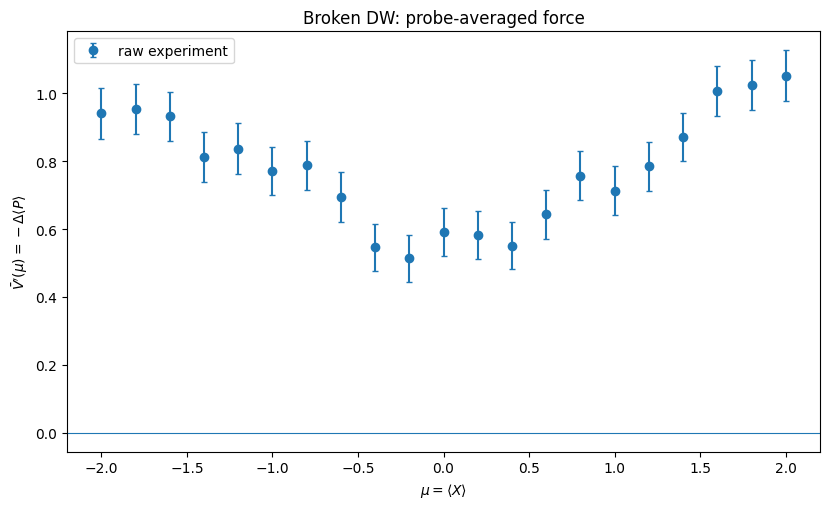

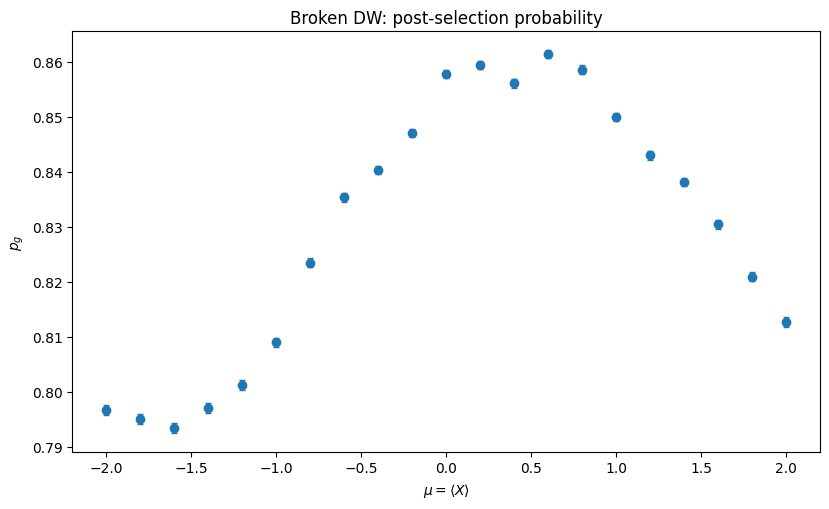

In [5]:
nom=[]
for i,r in enumerate(records):
    f=cf_fit(r,CF_ORDER)
    den=(1-frac[i])*cal0["den"]+frac[i]*cal1["den"]
    nom.append({"mu":r["mu"],"label":r["label"],"cal_fraction":frac[i],
                "denominator":den,"force":f["slope"]/den,
                "pg":r["pg"],"cf_p":f["p"]})
data=pd.DataFrame(nom).sort_values("mu").reset_index(drop=True)

Fb,Pgb=bootstrap_raw(records,cal0,cal1,frac,B=N_BOOT,seed=20260824,order=CF_ORDER)
covF=np.cov(Fb,rowvar=False,ddof=1)
covPg=np.cov(Pgb,rowvar=False,ddof=1)
data["force_se"]=np.sqrt(np.clip(np.diag(covF),0,np.inf))
data["pg_se"]=np.sqrt(np.clip(np.diag(covPg),0,np.inf))
display(data)
data.to_csv(OUT/"04_raw_force_acceptance.csv",index=False)

plt.figure(figsize=(8.4,5.2))
plt.errorbar(data.mu,data.force,yerr=data.force_se,fmt="o",capsize=2,label="raw experiment")
plt.axhline(0,linewidth=0.8)
plt.xlabel(r"$\mu=\langle X\rangle$")
plt.ylabel(r"$\bar V'(\mu)=-\Delta\langle P\rangle$")
plt.title("Broken DW: probe-averaged force")
plt.legend(); plt.tight_layout()
plt.savefig(OUT/"05_raw_force.png",dpi=300); plt.show()

plt.figure(figsize=(8.4,5.2))
plt.errorbar(data.mu,data.pg,yerr=data.pg_se,fmt="o",capsize=2)
plt.xlabel(r"$\mu=\langle X\rangle$"); plt.ylabel(r"$p_g$")
plt.title("Broken DW: post-selection probability")
plt.tight_layout(); plt.savefig(OUT/"06_pg.png",dpi=300); plt.show()

## 3. Compiled circuit
Built from the rotation angles that were run. $w=|K_g|^2$ and $q=-\mathrm{Im}[K_g^*K_g']$ are exact Fourier series of degree $M$, so the probe average of each is exact.

In [6]:
# =====================================================================
#  §3 --- THE COMPILED CIRCUIT.
#  Supplement, "Post-selected Kraus operator".
#
#  a(X) = |K_g|^2 and q(X) = -Im[K_g* K_g'] are EXACT finite Fourier series of
#  order M on the design period L, because K_g carries harmonics e^{i m gamma X}
#  with |m| <= M/2 of a single parity and both channels are quadratic in K_g.
#  Their coefficients come off by FFT to machine precision, and the
#  coherent-probe average is the closed form e^{-sigma^2 k^2/2} per harmonic.
# =====================================================================
# Broken-DW rotation angles actually run: 14 rotations, M = 13.
ROTS = [
    (0.21898,  1.10606, 0.809167),
    (1.11214,  3.92899, 0.0),
    (1.06721,  3.43005, 0.0),
    (1.18029,  3.0126,  0.0),
    (1.29495,  2.88874, 0.0),
    (1.19385,  1.66121, 0.0),
    (0.819419, 0.662157,0.0),
    (0.25738,  4.16433, 0.0),
    (0.831021, 1.55599, 0.0),
    (1.46442,  2.23498, 0.0),
    (1.34071,  2.94397, 0.0),
    (1.07443,  3.45289, 0.0),
    (0.930696, 0.443031,0.0),
    (0.399867, 1.45762, 0.0),
]

QSP_ORDER_M = len(ROTS) - 1
# BETA and L come from the configuration cell.
assert abs(BETA - 2*np.pi/L) < 1e-12, "BETA and L are inconsistent"


def R_general(theta, phi, lam):
    return np.array([[np.exp(1j*(lam+phi))*np.cos(theta), np.exp(1j*phi)*np.sin(theta)],
                     [np.exp(1j*lam)*np.sin(theta),      -np.cos(theta)]], complex)


_RL = [R_general(*r) for r in ROTS]


def K_Kp(x):
    """Compiled accepted branch K_g(x) and its exact derivative."""
    S_  = np.array([[0, np.exp(1j*BETA*x/2)],
                    [np.exp(-1j*BETA*x/2), 0]], complex)
    Sp_ = np.array([[0, 1j*BETA/2*np.exp(1j*BETA*x/2)],
                    [-1j*BETA/2*np.exp(-1j*BETA*x/2), 0]], complex)
    U  = _RL[0].copy(); Up = np.zeros((2, 2), complex)
    for j in range(1, len(_RL)):
        Up = _RL[j] @ (Sp_ @ U + S_ @ Up)
        U  = _RL[j] @ S_ @ U
    return U[0, 0], Up[0, 0]


def _channel_coeffs(nfft=512):
    xq = np.arange(nfft)/nfft*L
    v  = [K_Kp(float(t)) for t in xq]
    K  = np.array([z[0] for z in v]); Kp = np.array([z[1] for z in v])
    return np.fft.fft(np.abs(K)**2)/nfft, np.fft.fft(-np.imag(np.conj(K)*Kp))/nfft


CA, CQ = _channel_coeffs()
_tail = max(max(abs(CA[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)),
            max(abs(CQ[n]) for n in range(QSP_ORDER_M+1, QSP_ORDER_M+20)))
print(f"compiled channels are exact Fourier series of order M = {QSP_ORDER_M}: "
      f"largest coefficient above M = {_tail:.2e}")


def series(c, x, sigma2=0.0, M=None):
    """sum_{|n|<=M} c_n e^{i k_n x}, Gaussian-smoothed when sigma2 > 0.  Exact."""
    m = QSP_ORDER_M if M is None else int(M)
    x = np.asarray(x, float)
    out = np.full(np.shape(x), c[0].real, float)
    for n in range(1, m+1):
        k = 2*np.pi*n/L
        out = out + 2*np.exp(-0.5*sigma2*k*k)*(c[n].real*np.cos(k*x) - c[n].imag*np.sin(k*x))
    return out


def compiled_coherent(mu, sigma2=None):
    """Coherent-probe response -> (F_g, p_g)."""
    s2 = SIGMA2 if sigma2 is None else float(sigma2)
    pg = series(CA, mu, s2)
    return series(CQ, mu, s2)/pg, pg


_v  = [K_Kp(float(t)) for t in XGRID]
_K  = np.array([w[0] for w in _v]); _Kp = np.array([w[1] for w in _v])
XCOMP       = np.asarray(XGRID, float).copy()
AMPL_COMP   = np.abs(_K)
VPHASE_COMP = -np.unwrap(np.angle(_K))
VPHASE_COMP = VPHASE_COMP - np.interp(0.0, XGRID, VPHASE_COMP)
FPOINT_COMP = series(CQ, XGRID)/series(CA, XGRID)

_direct = -np.imag(np.conj(_K)*_Kp)/np.maximum(AMPL_COMP**2, 1e-12)
print(f"pointwise q/a, series vs direct matrix product: "
      f"max |diff| = {np.max(np.abs(FPOINT_COMP-_direct)):.2e}")

print(f"\ncompiled broken-DW gate: {len(ROTS)} rotations, M = {QSP_ORDER_M}")

compiled channels are exact Fourier series of order M = 13: largest coefficient above M = 7.27e-17
pointwise q/a, series vs direct matrix product: max |diff| = 4.44e-15

compiled broken-DW gate: 14 rotations, M = 13


## 4. Pointwise force reconstruction
### 4.1 Deconvolution and Sim
Acceptance and force channels normalised by $p_g(\mu=0)$, deconvolved separately by GLS on the resolved modes of the bootstrap covariance, $|n|\le n_{\max}$. Sim is the compiled circuit put through the same frozen inverse.

In [7]:
# Reconstruction input: every probe centre, |mu| <= L/2.  The compiled gate is
# periodic with period L, so mu = -L/2 and +L/2 are two measurements of the same
# point of the series; both are fitted.
REC_SEL = np.abs(data.mu.to_numpy(float)) <= L/2 + 1e-9
mu  = data.mu.to_numpy(float)[REC_SEL]
ch  = normalized_channels(mu, data.force.to_numpy(float)[REC_SEL], data.pg.to_numpy(float)[REC_SEL],
                          Fb[:, REC_SEL], Pgb[:, REC_SEL])
rec = deconvolve_gls(ch, mu, XGRID, NMAX, SIGMA2, L)
print(f"reconstruction input: {int(REC_SEL.sum())} of {len(REC_SEL)} probe centres (|mu| <= {L/2:g})")
PAPER["recon.input_probe_centres"] = int(REC_SEL.sum())

measured_support   = (XGRID >= data.mu.min()) & (XGRID <= data.mu.max())

gof = pd.DataFrame([
    {"channel":"normalised p_g   (A)", "chi2":rec["fit_a"]["chi2"], "dof":rec["fit_a"]["dof"],
     "p":rec["fit_a"]["p"], "resolved_cov_modes":rec["fit_a"]["cov_rank"]},
    {"channel":"normalised p_g F (Q)", "chi2":rec["fit_q"]["chi2"], "dof":rec["fit_q"]["dof"],
     "p":rec["fit_q"]["p"], "resolved_cov_modes":rec["fit_q"]["cov_rank"]},
])
display(gof); gof.to_csv(OUT/"16_deconvolution_gof.csv", index=False)
print(f"min reconstructed a(X) on measured support = {rec['a'][measured_support].min():.4f}")


# ---- Sim: the compiled circuit, probe-averaged at the same centres,
#      normalised as the data and put through the same frozen inverse -------
PG_COMP_MU = series(CA, mu, SIGMA2)
Q_COMP_MU  = series(CQ, mu, SIGMA2)
A_COMP_N = PG_COMP_MU/PG_COMP_MU[ch["i0"]]
Q_COMP_N = Q_COMP_MU/PG_COMP_MU[ch["i0"]]
_ac = rec["basis"] @ (rec["fit_a"]["H"] @ A_COMP_N)
_qc = rec["basis"] @ (rec["fit_q"]["H"] @ Q_COMP_N)
F_COMP_EST = np.where(_ac > rec["a_floor"], _qc/_ac, np.nan)


def integrate_masked(F_all, mask=None, zero_at=0.0, x_all=None):
    """Integrate a force curve that may carry NaN (where the reconstructed
    acceptance falls below a_floor) over its finite points only."""
    x = XGRID if x_all is None else np.asarray(x_all, float)
    F = np.asarray(F_all, float)
    ok = np.isfinite(F) if mask is None else (np.asarray(mask, bool) & np.isfinite(F))
    out = np.full(x.shape, np.nan, float)
    if int(ok.sum()) >= 2:
        out[ok] = integrate_force(x[ok], F[ok], zero_at=zero_at)
    return out

reconstruction input: 21 of 21 probe centres (|mu| <= 2)


,channel,chi2,dof,p,resolved_cov_modes
0,normalised p_g (A),329.065986,15,4.956036e-61,20
1,normalised p_g F (Q),10.190004,16,8.565191e-01,21


min reconstructed a(X) on measured support = 0.8136


### 4.2 Reconstructed force and potential

bootstrap draws usable for the potential: 2000 of 2000


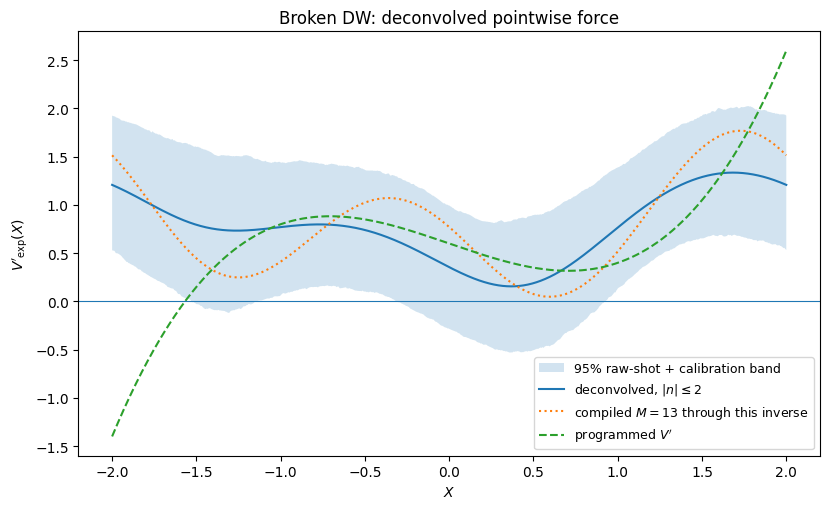

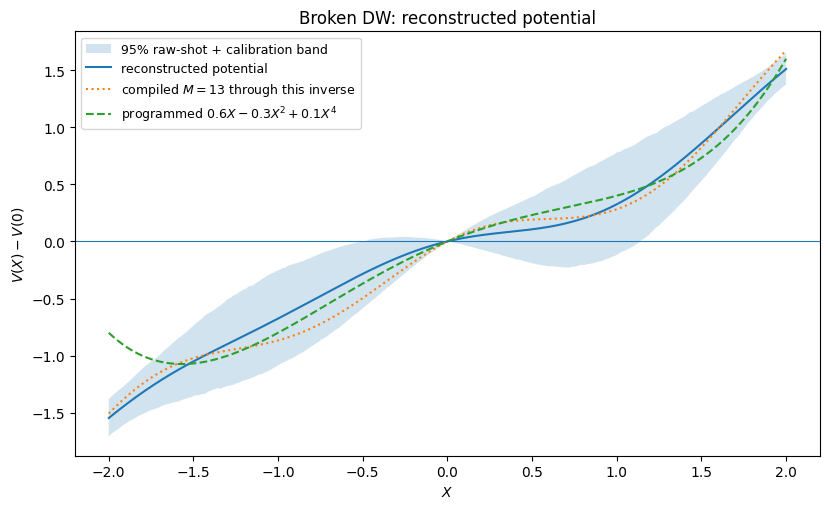

In [8]:
# The compiled curve overlaid here is Sim (F_COMP_EST, section 4.1): it has
# been through the same frozen inverse, and hence the same band limit, as the data.
boot_force = np.asarray(rec["force_boot"])
flo, fhi = np.nanpercentile(boot_force, [2.5, 97.5], axis=0)

xs   = XGRID[measured_support]
Vrec = integrate_force(xs, rec["force"][measured_support], zero_at=0.0)
Vb   = np.array([integrate_force(xs, f[measured_support], 0.0)
                 for f in boot_force if np.all(np.isfinite(f[measured_support]))])
vlo, vhi = np.nanpercentile(Vb, [2.5, 97.5], axis=0)
print(f"bootstrap draws usable for the potential: {len(Vb)} of {len(boot_force)}")

plt.figure(figsize=(8.4,5.2))
plt.fill_between(XGRID, flo, fhi, alpha=0.2, label="95% raw-shot + calibration band")
plt.plot(XGRID, rec["force"], label=fr"deconvolved, $|n|\leq{NMAX}$")
plt.plot(XGRID, F_COMP_EST, ":", label=fr"compiled $M={QSP_ORDER_M}$ through this inverse")
plt.plot(XGRID, dV_target(XGRID), "--", label=r"programmed $V'$")
plt.axhline(0, lw=0.8)
plt.xlabel("$X$"); plt.ylabel(r"$V'_{\rm exp}(X)$")
plt.title("Broken DW: deconvolved pointwise force")
plt.legend(fontsize=9); plt.tight_layout()
plt.savefig(OUT/"19_deconvolved_force.png", dpi=300); plt.show()

Vt_s = V_target(xs) - V_target(0.0)
plt.figure(figsize=(8.4,5.2))
plt.fill_between(xs, vlo, vhi, alpha=0.2, label="95% raw-shot + calibration band")
plt.plot(xs, Vrec, label="reconstructed potential")
plt.plot(xs, integrate_masked(F_COMP_EST, measured_support, zero_at=0.0)[measured_support], ":",
         label=fr"compiled $M={QSP_ORDER_M}$ through this inverse")
plt.plot(xs, Vt_s, "--", label=r"programmed $0.6X-0.3X^2+0.1X^4$")
plt.axhline(0, lw=0.8)
plt.xlabel("$X$"); plt.ylabel(r"$V(X)-V(0)$")
plt.title("Broken DW: reconstructed potential")
plt.legend(fontsize=9); plt.tight_layout()
plt.savefig(OUT/"20_reconstructed_potential.png", dpi=300); plt.show()

pd.DataFrame({"X":XGRID, "a":rec["a"], "q":rec["q"], "F_point":rec["force"],
              "F_lo95":flo, "F_hi95":fhi}).to_csv(OUT/"21_reconstruction_curves.csv", index=False)

### 4.3 The Morse-gate rule applied to this probe
The Morse reconstruction (`05_morse`, section 4) spends the noise budget of hard truncation at
the gain cap on a smooth rolloff through $|n|\le8$: harmonic $n$ is returned with gain
$g_n=H_n/(H_n^2+\epsilon n^2)$, with $\epsilon$ fixed by $\sum_{n=1}^{8}g_n^2=\sum_{n\le n_{\max}}H_n^{-2}$.
The fraction of harmonic $n$ it keeps is $H_ng_n$. Applied to this coherent probe, the rule is
compared here with the hard cut at $|n|\le n_{\max}$ used for this gate (SM *Pointwise force
reconstruction*). Nothing downstream uses it.

In [9]:
# =====================================================================
#  CROSS-CHECK: the regularised rule of the Morse gate on this probe.
#  eps is fixed by the gain cap alone, as in 05_morse.ipynb:
#      sum_{n=1..8} g_n^2 = sum_{n<=n_max} 1/H_n^2,   g_n = H_n/(H_n^2 + eps n^2)
#  and harmonic n keeps the fraction H_n g_n = H_n^2/(H_n^2 + eps n^2).
#  Only printed and quoted; this gate is reconstructed by hard truncation.
# =====================================================================
from scipy.optimize import brentq as _mr_brentq

MORSE_RULE_NMAX, MORSE_RULE_P = 8, 2           # as in 05_morse.ipynb


def _mr_H(n):
    return float(np.exp(-0.5*SIGMA2*(2*np.pi*n/L)**2))


_mr_target = sum(_mr_H(n)**-2 for n in range(1, NMAX + 1))
_mr_power = lambda eps: sum((_mr_H(n)/(_mr_H(n)**2 + eps*n**MORSE_RULE_P))**2
                            for n in range(1, MORSE_RULE_NMAX + 1))
MORSE_RULE_EPS = 10**_mr_brentq(lambda le: _mr_power(10**le) - _mr_target, -14, 2)
MORSE_RULE_KEPT = {n: _mr_H(n)**2/(_mr_H(n)**2 + MORSE_RULE_EPS*n**MORSE_RULE_P)
                   for n in range(1, MORSE_RULE_NMAX + 1)}

print(f"probe sigma_X^2 = {SIGMA2:.4f};  hard cut at the gain cap: |n| <= {NMAX}")
print(f"Morse-gate rule: eps = {MORSE_RULE_EPS:.3e}")
print(f"{'n':>4}{'1/H_n':>11}{'fraction kept':>15}")
for _n, _f in MORSE_RULE_KEPT.items():
    print(f"{_n:4d}{1/_mr_H(_n):11.3g}{_f:15.4f}")

probe sigma_X^2 = 0.5526;  hard cut at the gain cap: |n| <= 2
Morse-gate rule: eps = 5.185e-05
   n      1/H_n  fraction kept
   1       1.98         0.9998
   2       15.3         0.9538
   3        462         0.0099
   4   5.46e+04         0.0000
   5   2.52e+07         0.0000
   6   4.55e+10         0.0000
   7   3.21e+14         0.0000
   8   8.87e+18         0.0000


## 5. Band-limited target
The programmed force truncated to the retained harmonics $|n|\le n_{\max}$; it uses no data and isolates the distortion of the band limit itself.

In [10]:
# =====================================================================
#  BAND-LIMITED TARGET: the programmed force truncated to |n| <= n_max on
#  the Fourier interval [-L/2, L/2).  No data.
# =====================================================================
def band_limit(fn, nmax=None, L=L, nfft=8192):
    # truncate fn to |n| <= nmax harmonics on the design interval
    nm = NMAX if nmax is None else int(nmax)
    xq = -L/2 + np.arange(nfft)/nfft*L
    yq = np.asarray(fn(xq), float)
    c  = {n: np.mean(yq*np.exp(-1j*2*np.pi*n/L*xq)) for n in range(nm+1)}
    def g(xx):
        xx = np.asarray(xx, float)
        out = np.full(xx.shape, c[0].real)
        for n in range(1, nm+1):
            k = 2*np.pi*n/L
            out = out + 2*(c[n].real*np.cos(k*xx) - c[n].imag*np.sin(k*xx))
        return out
    return g


def stationary_points(y, x):
    # sign-change roots, near-duplicates merged
    y = np.asarray(y, float); r = []
    for i in np.where(np.diff(np.sign(y)) != 0)[0]:
        d = y[i+1] - y[i]
        xr = x[i] - y[i]*(x[i+1]-x[i])/d if d else x[i]
        if not r or abs(xr - r[-1]) > 1e-6:
            r.append(xr)
    return np.asarray(r)


_x = np.linspace(TOPOLOGY_WINDOW[0], TOPOLOGY_WINDOW[1], 200001)
print(f"stationary points on |X| <= {TOPOLOGY_WINDOW[1]}:")
print(f"  programmed    {np.round(stationary_points(dV_target(_x), _x), 4).tolist()}")
print(f"  band-limited  {np.round(stationary_points(band_limit(dV_target)(_x), _x), 4).tolist()}")

stationary points on |X| <= 1.5:
  programmed    []
  band-limited  []


## 6. Broken double well
### 6.1 Stationary points along the ladder
Zeros of the programmed force, the compiled force, Sim and the experiment, on the topology window and on the probed range.

In [11]:
# =====================================================================
#  §6.1 --- LADDERS.
#      programmed target -> compiled exact -> compiled through the estimator
#      -> experiment
#
#  The broken well is deliberately NOT a double well: for V = aX^4 - bX^2 + cX
#  a negative discriminant 8b^3 - 27ac^2 is the single-stationary-point
#  condition.  The ladder shows whether that survives the compilation and the
#  inverse before the device is involved.
#
#  Defines roots_dedup / LADDER_CURVES, reused by §6.2.
# =====================================================================

def roots_dedup(x, y, tol=1e-6):
    x = np.asarray(x, float); y = np.asarray(y, float)
    r, s = [], []
    for i in np.where(np.diff(np.sign(y)) != 0)[0]:
        d = y[i+1] - y[i]
        xr = x[i] - y[i]*(x[i+1]-x[i])/d if d else x[i]
        if r and abs(xr - r[-1]) <= tol:
            continue
        r.append(xr); s.append(d/(x[i+1]-x[i]))
    return np.asarray(r), np.asarray(s)


LADDER_CURVES = (
    ("programmed target",          np.asarray(dV_target(XGRID), float)),
    ("compiled exact",             np.asarray(FPOINT_COMP, float)),
    ("compiled through estimator", np.asarray(F_COMP_EST, float)),
    ("experiment",                 np.asarray(rec["force"], float)),
)

_ladder=[]
for _name,_curve in LADDER_CURVES:
    for _wlab,_mask in (("topology window", topology_support),
                        ("measured support", measured_support)):
        _rt, _ = roots_dedup(XGRID[_mask], _curve[_mask])
        _ladder.append({"curve":_name,"window":_wlab,
                        "n_stationary_points":len(_rt),
                        "stationary_points":np.round(_rt,4).tolist(),
                        "min_force":float(np.nanmin(_curve[_mask]))})
pb_root_ladder=pd.DataFrame(_ladder)
display(pb_root_ladder)
pb_root_ladder.to_csv(OUT/"22b_pb_stationary_point_ladder.csv",index=False)

,curve,window,n_stationary_points,stationary_points,min_force
0,programmed target,topology window,0,[],0.150000
1,programmed target,measured support,1,[-1.5675],-1.400000
2,compiled exact,topology window,1,[-1.4692],-0.306709
3,compiled exact,measured support,2,"[-1.7916, -1.4692]",-1.197647
4,compiled through estimator,topology window,0,[],0.048356
5,compiled through estimator,measured support,0,[],0.048356
6,experiment,topology window,0,[],0.155939
7,experiment,measured support,0,[],0.155939


### 6.2 Stationary points of the reconstruction and of its bootstrap
Fraction of bootstrap replicas with the minimum–barrier–minimum ordering on $|X|\le1.5$, and the number of zeros on the topology window and on the probed range (SM *Double-well gates: stationary points*).

In [12]:
# =====================================================================
#  STATIONARY POINTS OF THE BROKEN WELL
#  The programmed force has one zero, outside the topology window.  Counted
#  here for the programmed force, Sim and the experiment, and over the
#  bootstrap: minimum-barrier-minimum on |X| <= 1.5, and the number of
#  zeros on the topology window and on the whole probed range.
# =====================================================================
_pr = np.roots([4*A_TARGET, 0.0, -2*B_TARGET, C_TARGET])
BROKEN_TARGET_SP = np.sort(_pr[np.abs(_pr.imag) < 1e-9].real)
print(f"programmed stationary point(s): {np.round(BROKEN_TARGET_SP, 4)}")


def _mbm(f):
    r, s = roots_dedup(XGRID[topology_support], np.asarray(f)[topology_support])
    return bool(len(r) == 3 and s[0] > 0 and s[1] < 0 and s[2] > 0), len(r)


_res = [(_mbm(f), len(roots_dedup(XGRID[measured_support], f[measured_support])[0]))
        for f in boot_force if np.all(np.isfinite(f[measured_support]))]
BROKEN_TOPOLOGY_FRACTION = float(np.mean([a[0] for a, _ in _res]))
BROKEN_COUNTS_TOPOLOGY = pd.Series([a[1] for a, _ in _res]).value_counts(normalize=True).sort_index()
BROKEN_COUNTS_FULL = pd.Series([b for _, b in _res]).value_counts(normalize=True).sort_index()
BROKEN_NOMINAL = {name: roots_dedup(XGRID[measured_support], np.asarray(c)[measured_support])[0]
                  for name, c in LADDER_CURVES}
print(f"minimum-barrier-minimum on |X| <= {TOPOLOGY_WINDOW[1]} in "
      f"{100*BROKEN_TOPOLOGY_FRACTION:.1f}% of {len(_res)} replicas")
print("zeros on the topology window, bootstrap fractions:", BROKEN_COUNTS_TOPOLOGY.round(4).to_dict())
print("zeros on the probed range, bootstrap fractions:   ", BROKEN_COUNTS_FULL.round(4).to_dict())
for k, v in BROKEN_NOMINAL.items():
    print(f"  {k:28s} zeros on the probed range: {np.round(v, 3)}")

programmed stationary point(s): [-1.5675]
minimum-barrier-minimum on |X| <= 1.5 in 2.8% of 2000 replicas
zeros on the topology window, bootstrap fractions: {0: 0.5095, 2: 0.4335, 3: 0.028, 4: 0.029}
zeros on the probed range, bootstrap fractions:    {0: 0.5095, 2: 0.4275, 4: 0.063}
  programmed target            zeros on the probed range: [-1.567]
  compiled exact               zeros on the probed range: [-1.792 -1.469]
  compiled through estimator   zeros on the probed range: []
  experiment                   zeros on the probed range: []


### 6.3 Parity test on the raw force
$s_i=\bar V'(\mu_i)+\bar V'(-\mu_i)$ over the mirror pairs, $\chi^2=s^\top\Sigma_s^{-1}s$ with the bootstrap covariance of the sums. No reconstruction, no target (SM *Double-well gates: programmable asymmetry*).

In [13]:
# =====================================================================
#  PARITY TEST ON THE RAW FORCE.  Null: the implemented potential is even,
#  so the measured force is odd in the probe centre, F(+mu) = -F(-mu).
#  s_i = F(+mu_i) + F(-mu_i) over the mirror pairs, chi2 = s^T Sigma_s^-1 s
#  with Sigma_s the raw-shot bootstrap covariance of the sums.  No inverse,
#  no target.
# =====================================================================
# every probe, including mu = +/-L/2: no periodic model enters this test
_mu_all = data.mu.to_numpy(float)
_F_all = data.force.to_numpy(float)
_Fb_all = np.asarray(Fb, float)

_mu_u = np.unique(np.round(_mu_all, 9))
_T = np.zeros((len(_mu_u), len(_mu_all)))
for _r, _m in enumerate(_mu_u):
    _ix = np.where(np.isclose(_mu_all, _m))[0]
    _T[_r, _ix] = 1.0/len(_ix)
_F_u, _Fb_u = _T @ _F_all, _Fb_all @ _T.T

_pos = np.array([i for i in np.where(_mu_u > 1e-9)[0]
                 if np.any(np.isclose(_mu_u, -_mu_u[i]))], int)
_neg = np.array([int(np.where(np.isclose(_mu_u, -_mu_u[i]))[0][0]) for i in _pos])
_s = _F_u[_pos] + _F_u[_neg]
_Cs = np.cov(_Fb_u[:, _pos] + _Fb_u[:, _neg], rowvar=False, ddof=1)
_Cs = (_Cs + _Cs.T)/2
_ev, _U = np.linalg.eigh(_Cs)
_keep = _ev > max(float(_ev.max())*1e-10, 1e-18)
_chi = float(_s @ ((_U[:, _keep]/_ev[_keep]) @ _U[:, _keep].T) @ _s)
_dof = int(_keep.sum())
PARITY_TEST = {"chi2": _chi, "dof": _dof, "p": float(chi2_dist.sf(_chi, _dof))}

anti = pd.DataFrame({"mu": _mu_u[_pos], "F_plus": _F_u[_pos], "F_minus": _F_u[_neg],
                     "sum": _s, "se_sum": np.sqrt(np.clip(np.diag(_Cs), 0, np.inf))})
anti["z"] = anti["sum"]/anti["se_sum"]
display(anti.round(4))
anti.to_csv(OUT / "parity_test.csv", index=False)
print(f"{len(_mu_all)} force points -> {len(_mu_u)} probe centres, {len(_pos)} mirror pairs")
print(f"null 'V is even': chi2 = {_chi:.1f}/{_dof}, p = {PARITY_TEST['p']:.3g}")

,mu,F_plus,F_minus,sum,se_sum,z
0,0.2,0.5820,0.5132,1.0953,0.1000,10.9480
1,0.4,0.5512,0.5455,1.0967,0.0982,11.1716
2,0.6,0.6431,0.6938,1.3369,0.1033,12.9461
3,0.8,0.7572,0.7883,1.5455,0.1028,15.0388
4,1.0,0.7134,0.7712,1.4846,0.1020,14.5541
5,1.2,0.7848,0.8371,1.6219,0.1061,15.2881
6,1.4,0.8702,0.8109,1.6811,0.1042,16.1412
7,1.6,1.0060,0.9323,1.9382,0.1054,18.3932
8,1.8,1.0235,0.9525,1.9760,0.1089,18.1428
9,2.0,1.0522,0.9406,1.9928,0.1047,19.0390


21 force points -> 21 probe centres, 10 mirror pairs
null 'V is even': chi2 = 1709.7/10, p = 0


## 7. Acceptance and post-selection
Compiled acceptance $A_M^2$, its probe average, and the measured $p_g$ over the topology window (SM *Acceptance and post-selection*).

In [14]:
# =====================================================================
#  ACCEPTANCE AND POST-SELECTION over the analysis window
#    A_M^2         compiled acceptance |K_g(X)|^2, pointwise over the window
#    <A_M^2>_mu    compiled acceptance averaged over the probe, at the probe
#                  centres in the window
#    p_g           measured post-selection probability at the same centres
# =====================================================================
ACC_WINDOW = float(TOPOLOGY_WINDOW[1])
_xg = np.linspace(-ACC_WINDOW, ACC_WINDOW, 2001)
_mu = data.mu.to_numpy(float)
_sel = np.abs(_mu) <= ACC_WINDOW + 1e-9
ACCEPTANCE = {"A_M^2 pointwise": series(CA, _xg),
              "<A_M^2>_mu": compiled_coherent(_mu[_sel])[1],
              "p_g measured": data.pg.to_numpy(float)[_sel]}
acc_tbl = pd.DataFrame([{"quantity": k, "mean": np.mean(v), "min": np.min(v),
                         "max": np.max(v), "n": len(v)} for k, v in ACCEPTANCE.items()])
print(f"acceptance over |X| <= {ACC_WINDOW:g}:")
display(acc_tbl.round(4))
acc_tbl.to_csv(OUT / "acceptance_window.csv", index=False)

acceptance over |X| <= 1.5:


,quantity,mean,min,max,n
0,A_M^2 pointwise,0.9605,0.8124,1.0000,2001
1,<A_M^2>_mu,0.9496,0.9154,0.9689,15
2,p_g measured,0.8385,0.7971,0.8613,15


## 8. Agreement with Sim
Over each window: the fraction in which Sim lies inside the 95% bootstrap band of the
reconstruction (the shaded region of the figures), and the r.m.s. difference between the measured
probe-averaged forces and the compiled response, relative to the r.m.s. bootstrap error of the
measured forces and to the r.m.s. compiled response (SM *Agreement with Sim*).

In [15]:
# =====================================================================
#  §8 --- AGREEMENT WITH SIM, over each window W:
#    coverage     fraction of |X| <= W (uniform grid) in which Sim lies inside
#                 the 95% bootstrap band of the reconstruction, i.e. the
#                 shaded region of the figures
#    point error  r.m.s. of (measured - compiled) probe-averaged force over the
#                 probe centres in |X| <= W, relative to the r.m.s. of the
#                 compiled response there; no reconstruction enters
#    point noise  r.m.s. bootstrap error of those measured forces, in the same
#                 units
#    ratio        point error / point noise: near 1 means the measured forces
#                 differ from the compiled response by the noise alone
# =====================================================================
_mu_p = data.mu.to_numpy(float)
_F_p = data.force.to_numpy(float)
_C_p = np.cov(np.asarray(Fb, float), rowvar=False, ddof=1)
_se_p = np.sqrt(np.clip(np.diag(_C_p), 0, None))
_F_c = np.asarray(compiled_coherent(_mu_p)[0], float)

_X = np.asarray(XGRID, float)
_F_sim = np.asarray(F_COMP_EST, float)                   # Sim
_lo, _hi = np.asarray(flo, float), np.asarray(fhi, float)

_wins = {f"topology window |X| <= {float(TOPOLOGY_WINDOW[1]):g}": float(TOPOLOGY_WINDOW[1]),
         "full range |X| <= 2": L/2 + 1e-6}

def _rms(v):
    v = np.asarray(v, float)
    return float(np.sqrt(np.mean(v**2)))


def agreement_with_sim(W):
    gx = (np.abs(_X) <= W + 1e-9) & np.isfinite(_F_sim) & np.isfinite(_lo) & np.isfinite(_hi)
    inside = (_F_sim[gx] >= _lo[gx]) & (_F_sim[gx] <= _hi[gx])
    gp = np.abs(_mu_p) <= W + 1e-9
    err, noise = _rms(_F_p[gp] - _F_c[gp]), _rms(_se_p[gp])
    return {"W": min(float(W), 2.0), "coverage": float(inside.mean()), "probes": int(gp.sum()),
            "point_error": err/_rms(_F_c[gp]), "point_noise": noise/_rms(_F_c[gp]),
            "ratio": err/noise}


_rows = []
for _name, _W in _wins.items():
    _r = agreement_with_sim(_W)
    _rows.append({"range": _name, **_r})
    PAPER[f"agreement.{_name.split(' |')[0].replace(' ', '_')}.W_coverage_ratio_pointerr_pointnoise"] = [
        _r["W"], _r["coverage"], _r["ratio"], _r["point_error"], _r["point_noise"]]
AGREEMENT = pd.DataFrame(_rows)
AGREEMENT.to_csv(OUT / "agreement_with_sim.csv", index=False)
print("Sim against the data (point error and noise relative to the r.m.s. compiled response):")
display(AGREEMENT.round(4))

Sim against the data (point error and noise relative to the r.m.s. compiled response):


,range,W,coverage,probes,point_error,point_noise,ratio
0,topology window |X| <= 1.5,1.5,1.0,15,0.0973,0.0968,1.0046
1,full range |X| <= 2,2.0,1.0,21,0.0789,0.0890,0.8869


## 9. Values quoted in the paper

In [16]:
# =====================================================================
#  VALUES QUOTED IN THE PAPER -- broken double well
# =====================================================================
P = PAPER
P["acq.probe"] = "coherent"
P["acq.scans"] = 1
P["acq.probe_centres"] = len(records)
P["acq.reps_per_cf_point"] = sorted({int(r["N"]) for r in records})
P["acq.cf_points_per_cut"] = sorted({int(r["ncf"]) for r in records})
P["acq.binary_outcomes"] = int(sum(int(r["N"])*int(r["ncf"]) for r in records))
P["acq.vacuum_calibrations"] = len(cross)
P["cal.Lambda"] = [float(c["primary"]["den"]) for c in cross]
P["cal.Lambda_se"] = [float(c["primary"]["se"]) for c in cross]
P["cal.cf_fit_degree"] = int(CF_ORDER)
P["cal.crosshair_sigma_X2"] = [float(v) for v in SIGMA2_MEASURED]
# ---- probe and bandwidth -----------------------------------------------
P["probe.sigma_X2"] = float(SIGMA2)
P["bandwidth.n_max"] = int(NMAX)
P["bandwidth.inverse_gain_n1..nmax+1"] = [float(np.exp(0.5*SIGMA2*(2*np.pi*n/L)**2))
                                          for n in range(1, NMAX + 2)]
# ---- compiled circuit ----------------------------------------------------
P["circuit.M"] = int(QSP_ORDER_M)
# ---- reconstruction --------------------------------------------------------
P["recon.w_channel.chi2_dof_p"] = [rec["fit_a"]["chi2"], rec["fit_a"]["dof"], rec["fit_a"]["p"]]
P["recon.q_channel.chi2_dof_p"] = [rec["fit_q"]["chi2"], rec["fit_q"]["dof"], rec["fit_q"]["p"]]
P["recon.min_w_on_probed_range"] = float(np.min(rec["a"][measured_support]))
P["recon.bootstrap_replicas"] = int(np.asarray(rec["force_boot"]).shape[0])
# ---- acceptance --------------------------------------------------------------
P["acceptance.window"] = ACC_WINDOW
for _k, _v in ACCEPTANCE.items():
    P[f"acceptance.{_k}.mean_min_max"] = [float(np.mean(_v)), float(np.min(_v)), float(np.max(_v))]

# ---- stationary points and parity -------------------------------------------
P["topology.window"] = float(TOPOLOGY_WINDOW[1])
P["broken.programmed_stationary_points"] = BROKEN_TARGET_SP.tolist()
P["broken.fraction_min_barrier_min"] = BROKEN_TOPOLOGY_FRACTION
P["broken.zero_count_fractions_topology_window"] = {int(k): float(v) for k, v in BROKEN_COUNTS_TOPOLOGY.items()}
P["broken.zero_count_fractions_probed_range"] = {int(k): float(v) for k, v in BROKEN_COUNTS_FULL.items()}
for _k, _v in BROKEN_NOMINAL.items():
    P[f"broken.zeros_probed_range.{_k}"] = np.asarray(_v).tolist()
P["parity.chi2_dof_p"] = [PARITY_TEST["chi2"], PARITY_TEST["dof"], PARITY_TEST["p"]]
# ---- the Morse-gate rule applied to this probe (section 4) ----------------------
P["crosscheck.morse_rule.eps"] = float(MORSE_RULE_EPS)
P["crosscheck.morse_rule.kept_fraction_n1..8"] = [float(MORSE_RULE_KEPT[n])
                                                   for n in range(1, MORSE_RULE_NMAX + 1)]

In [17]:
# =====================================================================
#  Print the collected values between fixed markers (read by
#  extract_outputs.py) and write them to OUT/paper_values.json.
# =====================================================================
def _plain(v):
    if isinstance(v, dict):
        return {str(k): _plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [_plain(x) for x in list(np.asarray(v, dtype=object).ravel())] \
            if isinstance(v, np.ndarray) else [_plain(x) for x in v]
    if isinstance(v, (np.bool_, bool)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return float(v)
    return v


def _fmt(v):
    v = _plain(v)
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return str(v)
    if isinstance(v, float):
        if not np.isfinite(v):
            return "nan"
        return f"{v:.4g}" if (v == 0 or 1e-3 <= abs(v) < 1e5) else f"{v:.3e}"
    if isinstance(v, list):
        return "[" + ", ".join(_fmt(x) for x in v) + "]"
    if isinstance(v, dict):
        return "{" + ", ".join(f"{k}: {_fmt(x)}" for k, x in v.items()) + "}"
    return str(v)


import json
print(f"===== PAPER VALUES: {GATE} =====")
for _k, _v in PAPER.items():
    print(f"{_k} = {_fmt(_v)}")
print(f"===== END PAPER VALUES: {GATE} =====")
(OUT / "paper_values.json").write_text(json.dumps(_plain(PAPER), indent=1, default=str))

===== PAPER VALUES: broken double well =====
recon.input_probe_centres = 21
agreement.topology_window.W_coverage_ratio_pointerr_pointnoise = [1.5, 1, 1.005, 0.09726, 0.09681]
agreement.full_range.W_coverage_ratio_pointerr_pointnoise = [2, 1, 0.8869, 0.07892, 0.08898]
acq.probe = coherent
acq.scans = 1
acq.probe_centres = 21
acq.reps_per_cf_point = [10000]
acq.cf_points_per_cut = [21]
acq.binary_outcomes = 4410000
acq.vacuum_calibrations = 2
cal.Lambda = [1.84, 1.879]
cal.Lambda_se = [0.03014, 0.03777]
cal.cf_fit_degree = 5
cal.crosshair_sigma_X2 = [0.5494, 0.5557]
probe.sigma_X2 = 0.5526
bandwidth.n_max = 2
bandwidth.inverse_gain_n1..nmax+1 = [1.977, 15.28, 461.9]
circuit.M = 13
recon.w_channel.chi2_dof_p = [329.1, 15, 4.956e-61]
recon.q_channel.chi2_dof_p = [10.19, 16, 0.8565]
recon.min_w_on_probed_range = 0.8136
recon.bootstrap_replicas = 2000
acceptance.window = 1.5
acceptance.A_M^2 pointwise.mean_min_max = [0.9605, 0.8124, 1]
acceptance.<A_M^2>_mu.mean_min_max = [0.9496, 0.9154, 0.

2574

## 10. Figures
Main-text Fig. 3(a): broken-well force and potential panels. `SAVE_FOR_EXPORT = True` writes bare SVG panels (no text) for assembly.

bootstrap draws usable for the potential: 2000 of 2000
compiled curve plotted: compiled through $|n|\leq2$ inverse   (COMPILED_THROUGH_ESTIMATOR = True)


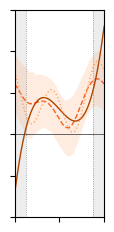

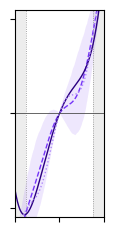

In [18]:
# =====================================================================
#  §10 --- Styled broken-DW force and potential panels for export.
#  Same figure pair, same estimator and same band as the other gates: the
#  experimental curve is the DECONVOLUTION (rec["force"]) with its raw-shot
#  bootstrap band, and the compiled curve is the one that has been through
#  the same frozen inverse (see the flag below).  This is the styled version
#  of the reconstruction of section 4.2.
#
#  COMPILED_THROUGH_ESTIMATOR selects which compiled curve is drawn:
#    True   the compiled circuit after the frozen n_max inverse (F_COMP_EST,
#           built in section 4.1).  Like-for-like against the data, since
#           both have been through the same band limit.  This is the default.
#    False  the exact compiled pointwise force (FPOINT_COMP) and, for the
#           potential, the compiled phase profile VPHASE_COMP.  The ceiling
#           the inverse is trying to reach, not a fair comparison to the data.
#
#  Note the two branches do not plot the same KIND of object in the potential
#  figure: True integrates the band-limited force, False shows -arg(K_g).
#  They differ by the band limit, which is the point of the switch.
#
# =====================================================================
from matplotlib.ticker import MultipleLocator

SAVE_FOR_EXPORT = True   # True: no title/axis labels/tick numbers, small figsize
                         # False: title + axis labels, bigger preview figsize

CM = 1 / 2.54
FIGSIZE_EXPORT  = (3 * CM, 6 * CM)
FIGSIZE_PREVIEW = (8.4, 5.2)
FIGSIZE = FIGSIZE_EXPORT if SAVE_FOR_EXPORT else FIGSIZE_PREVIEW

LW = 1.0
MARKER_EVERY = None
MARKER       = "o"
MARKER_SIZE  = 2.5

# --- force plot: all orange, three shades -------------------------------
FORCE_COLOR_TARGET   = "#AE4500"   # dark orange  — programmed target
FORCE_COLOR_RECON    = "#FB6023"   # mid orange   — deconvolved experiment
FORCE_COLOR_COMPILED = "#FFA366"   # light orange — compiled accepted branch

# --- potential plot: all purple, matching shades/linestyles -------------
POT_COLOR_TARGET   = "#2A0080"
POT_COLOR_RECON    = "#7534F8"
POT_COLOR_COMPILED = "#AE88F9"

LS_RECON, LS_TARGET, LS_COMPILED = "--", "-", ":"
COLOR_BOUNDARY = "0.55"

# --- axis limits / ticks, per plot --------------------------------------
XLIM = (-2.0, 2.0)
YLIM_FORCE     = (-2.0, 3.0)
YLIM_POTENTIAL = (-1.1, 1.1)
XTICK_STEP_FORCE     = 2.0
YTICK_STEP_FORCE     = 1.0
XTICK_STEP_POTENTIAL = 2.0
YTICK_STEP_POTENTIAL = 1.0

# Which compiled curve to draw; see the header.  True is the like-for-like
# comparison against the data and is what the paper figures use.
COMPILED_THROUGH_ESTIMATOR = True

DESIGN_HALF_WIDTH = 2.0
BOUNDARY_INNER = TOPOLOGY_WINDOW[-1]

plt.rcParams.update({
    "font.size": 8,
    "font.family": "sans-serif",
    "font.sans-serif": ["Calibri"],
    "figure.facecolor": "none",
    "axes.facecolor": "none",
    "savefig.transparent": True,
    "svg.fonttype": "none",
})

marker_kwargs = dict(marker=MARKER, markevery=MARKER_EVERY, markersize=MARKER_SIZE) \
                if MARKER_EVERY else {}


def add_design_range_shading(ax):
    for sign in (+1, -1):
        lo, hi = sorted((sign * BOUNDARY_INNER, sign * DESIGN_HALF_WIDTH))
        ax.axvspan(lo, hi, color=COLOR_BOUNDARY, alpha=0.15, lw=0, zorder=0)
        ax.axvline(sign * BOUNDARY_INNER, color=COLOR_BOUNDARY,
                   linestyle=":", linewidth=0.6, zorder=1)


def style_axes(ax, title, xlabel, ylabel):
    if not SAVE_FOR_EXPORT:
        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    else:
        ax.tick_params(labelbottom=False, labelleft=False)


def apply_axis_limits(ax, ylim=None, xtick=None, ytick=None):
    ax.set_xlim(XLIM)
    if ylim is not None and ylim != (None, None):
        ax.set_ylim(ylim)
    if xtick is not None:
        ax.xaxis.set_major_locator(MultipleLocator(xtick))
    if ytick is not None:
        ax.yaxis.set_major_locator(MultipleLocator(ytick))


# ============================================================
#  Data prep.  Potentials are referenced to X = 0, as in section 4.2: the
#  broken well has no barrier to reference to.
# ============================================================
xs = XGRID[measured_support]
vref = 0.0

Vrec = integrate_force(xs, rec["force"][measured_support], zero_at=vref)
vb = np.array([integrate_force(xs, f[measured_support], vref)
               for f in boot_force if np.all(np.isfinite(f[measured_support]))])
vlo, vhi = np.nanpercentile(vb, [2.5, 97.5], axis=0)
print(f"bootstrap draws usable for the potential: {len(vb)} of {len(boot_force)}")

Vtar_s = V_target(xs) - V_target(vref)

if COMPILED_THROUGH_ESTIMATOR:
    # F_COMP_EST is built on XGRID (section 4.1), so it is not resampled.
    assert np.shape(F_COMP_EST) == np.shape(XGRID), "F_COMP_EST must be on XGRID"
    Fcomp = np.asarray(F_COMP_EST, float)
    Vcomp = integrate_masked(Fcomp, measured_support, zero_at=vref)[measured_support]
    _comp_label = fr"compiled through $|n|\leq{NMAX}$ inverse"
else:
    Fcomp = np.interp(XGRID, XCOMP, FPOINT_COMP)
    Vcomp = np.interp(xs, XCOMP, VPHASE_COMP)
    Vcomp = Vcomp - np.interp(vref, xs, Vcomp)
    _comp_label = "compiled accepted branch"

print(f"compiled curve plotted: {_comp_label}"
      f"   (COMPILED_THROUGH_ESTIMATOR = {COMPILED_THROUGH_ESTIMATOR})")


# ============================================================
#  Figure 1: pointwise force  (all orange)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(XGRID, flo, fhi, color=FORCE_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(XGRID, rec["force"], LS_RECON, color=FORCE_COLOR_RECON, lw=LW,
        label=fr"deconvolved, $|n|\leq{NMAX}$", **marker_kwargs)
ax.plot(XGRID, dV_target(XGRID), LS_TARGET, color=FORCE_COLOR_TARGET, lw=LW,
        label=r"programmed $V'(X)=0.6-0.6X+0.4X^3$")
ax.plot(XGRID, Fcomp, LS_COMPILED, color=FORCE_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_FORCE, xtick=XTICK_STEP_FORCE, ytick=YTICK_STEP_FORCE)
style_axes(ax, "Broken DW: deconvolved pointwise force", r"$X$", r"$V'_{\rm exp}(X)$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "12_force_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  Figure 2: potential  (all purple, matching linestyles)
# ============================================================
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.fill_between(xs, vlo, vhi, color=POT_COLOR_COMPILED, alpha=0.2, lw=0,
                label="95% raw-shot + calibration band")
ax.plot(xs, Vrec, LS_RECON, color=POT_COLOR_RECON, lw=LW,
        label="reconstructed potential", **marker_kwargs)
ax.plot(xs, Vtar_s, LS_TARGET, color=POT_COLOR_TARGET, lw=LW,
        label=r"programmed $0.6X-0.3X^2+0.1X^4$")
ax.plot(xs, Vcomp, LS_COMPILED, color=POT_COLOR_COMPILED, lw=LW, label=_comp_label)
ax.axhline(0, lw=0.6, color="0.3")
add_design_range_shading(ax)
apply_axis_limits(ax, ylim=YLIM_POTENTIAL, xtick=XTICK_STEP_POTENTIAL, ytick=YTICK_STEP_POTENTIAL)
style_axes(ax, "Broken DW: reconstructed potential", r"$X$", r"$V(X)-V(0)$")
if not SAVE_FOR_EXPORT:
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "13_potential_vs_target.svg", format="svg", transparent=True)
plt.show()


# ============================================================
#  CSV export
# ============================================================
pd.DataFrame({
    "X": XGRID, "a": rec["a"], "q": rec["q"],
    "F_point": rec["force"], "F_lo95": flo, "F_hi95": fhi,
    "F_programmed": dV_target(XGRID),
    "F_compiled_plotted": Fcomp,
    "F_compiled_through_estimator": np.asarray(F_COMP_EST, float),
    "F_compiled_exact": np.interp(XGRID, XCOMP, FPOINT_COMP),
    "A_compiled": np.interp(XGRID, XCOMP, AMPL_COMP),
}).to_csv(OUT / "23_reconstruction_curves.csv", index=False)